# AI4I 2020 Predictive Maintenance — Phase 1

**Machine Learning Lab | Dataset analysis and preprocessing plan**

## 1. Import the libraries

These are the libraries used in the lab for data handling, visualisation and preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the dataset

Keep `ai4i2020.csv` in the same folder as this notebook. The dataset is loaded using Pandas `read_csv()`.


In [4]:
df = pd.read_csv("../data/ai4i2020.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of rows: 10000
Number of columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Dataset metadata

The dataset contains identifiers, product type, machine measurements and failure labels. The target for this project is `Machine failure`.

In [5]:
metadata = pd.DataFrame({
    "Column": [
        "UDI", "Product ID", "Type", "Air temperature [K]",
        "Process temperature [K]", "Rotational speed [rpm]",
        "Torque [Nm]", "Tool wear [min]", "Machine failure",
        "TWF", "HDF", "PWF", "OSF", "RNF"
    ],
    "Description": [
        "Unique row identifier",
        "Product identifier",
        "Product quality type: L, M or H",
        "Air temperature in Kelvin",
        "Process temperature in Kelvin",
        "Rotation speed in revolutions per minute",
        "Torque in Newton-metres",
        "Tool wear in minutes",
        "Target: 0 means no failure and 1 means failure",
        "Tool Wear Failure indicator",
        "Heat Dissipation Failure indicator",
        "Power Failure indicator",
        "Overstrain Failure indicator",
        "Random Failure indicator"
    ],
    "Role": [
        "Identifier - not used as a model input",
        "Identifier - not used as a model input",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Target variable",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs"
    ]
})

metadata

,Column,Description,Role
0,UDI,Unique row identifier,Identifier - not used as a model input
1,Product ID,Product identifier,Identifier - not used as a model input
2,Type,"Product quality type: L, M or H",Input feature
3,Air temperature [K],Air temperature in Kelvin,Input feature
4,Process temperature [K],Process temperature in Kelvin,Input feature
5,Rotational speed [rpm],Rotation speed in revolutions per minute,Input feature
6,Torque [Nm],Torque in Newton-metres,Input feature
7,Tool wear [min],Tool wear in minutes,Input feature
8,Machine failure,Target: 0 means no failure and 1 means failure,Target variable
9,TWF,Tool Wear Failure indicator,Failure subtype - excluded from inputs


## 4. Basic inspection

First, inspect the data types and summary statistics. This is the same kind of initial check used in the Pandas lab exercises.

In [6]:
print("Data types and non-missing values:")
df.info()

print("\n summary:")
df.describe()

Data types and non-missing values:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtyp

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 5. Check missing values and duplicate rows

This check helps identify data-quality issues before doing any analysis.

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Number of duplicate rows: 0


## 6. Check the target variable

`Machine failure` is the target variable. Since it has two classes (0 and 1), this is a **binary classification** problem.

Target values:
Machine failure
0    9661
1     339
Name: count, dtype: int64


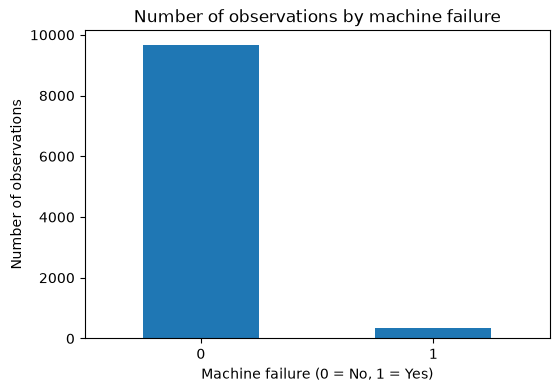

In [9]:
print("Target values:")
print(df["Machine failure"].value_counts())

plt.figure(figsize=(6, 4))
df["Machine failure"].value_counts().plot(kind="bar")
plt.title("Number of observations by machine failure")
plt.xlabel("Machine failure (0 = No, 1 = Yes)")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.show()

## 7. Explore the numerical features

The five measurements below are numerical inputs. Histograms help show their distributions and possible unusual values.

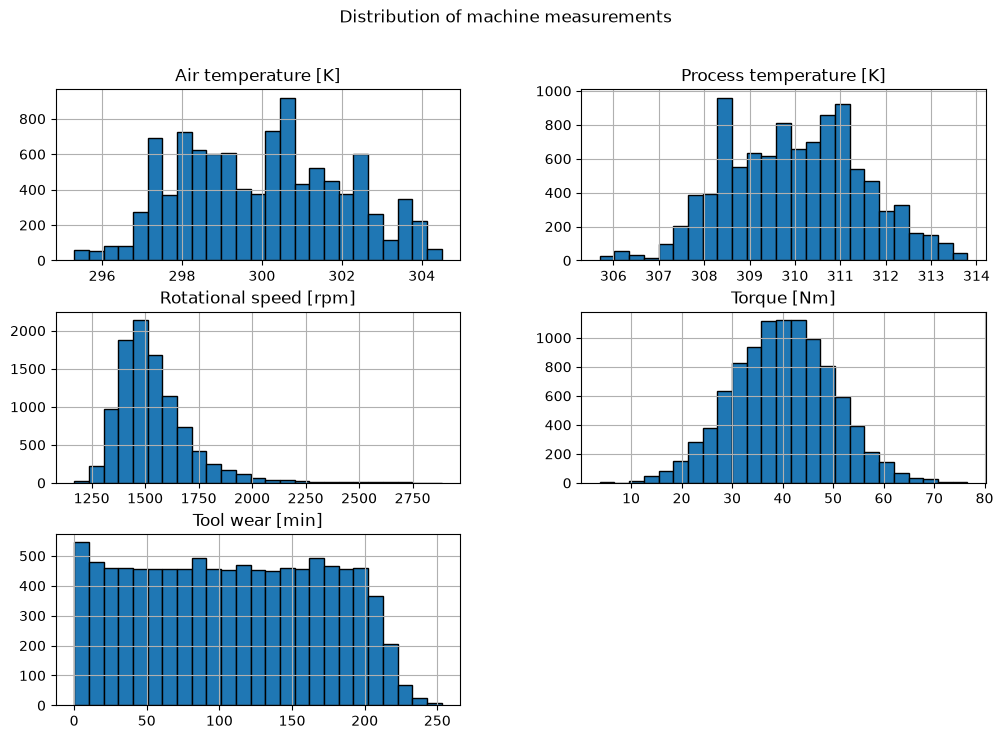

In [10]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(figsize=(12, 8), bins=25, edgecolor="black")
plt.suptitle("Distribution of machine measurements")
plt.show()

## 8. Compare measurements by failure status

Boxplots help compare the median and spread of each measurement for observations with and without a recorded failure. The plot alone does not prove that a feature causes failure.

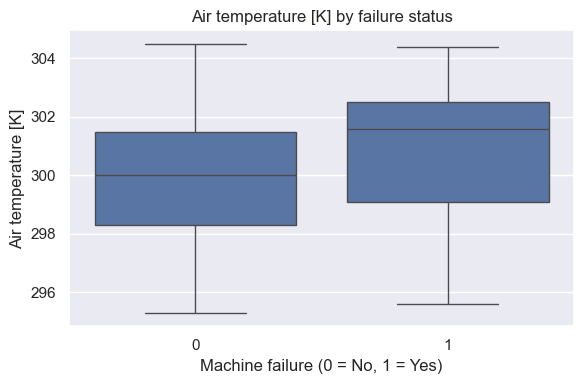

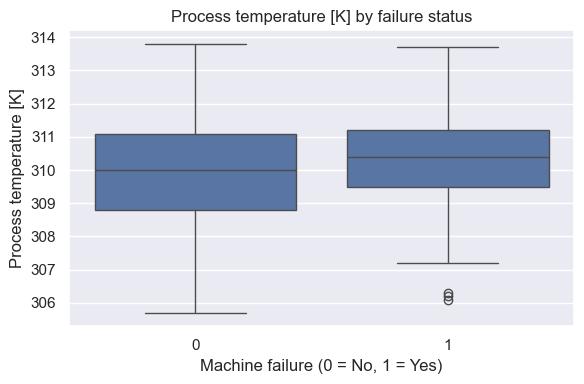

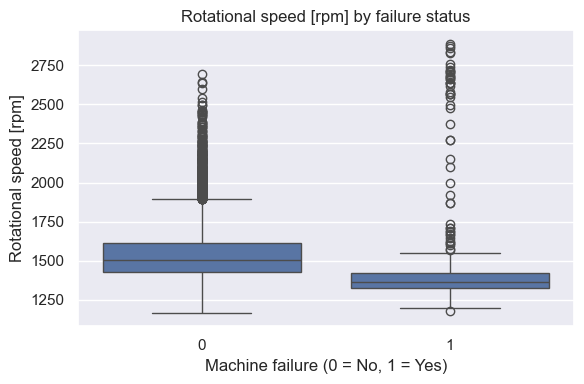

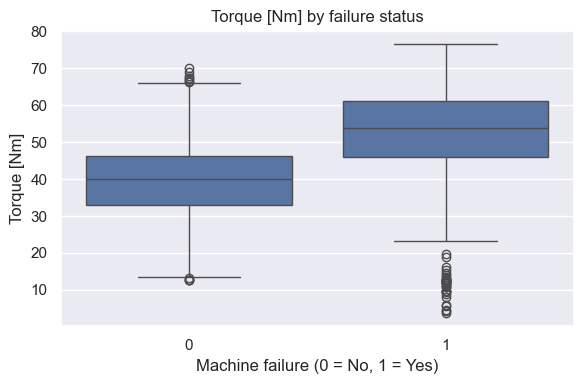

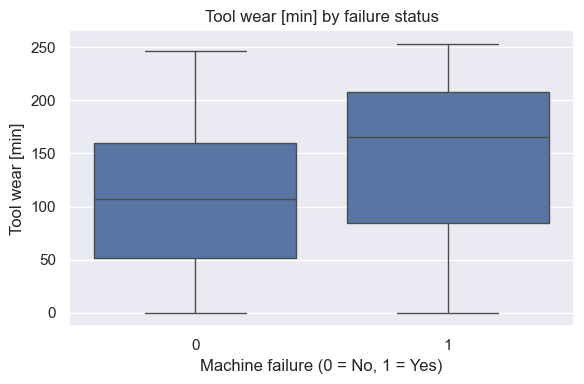

In [38]:
for column in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Machine failure", y=column)
    plt.title(column + " by failure status")
    plt.xlabel("Machine failure (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

## 9. Numerical summary by target class

Grouping the data by `Machine failure` gives a simple numerical comparison of the two classes.

In [11]:

df.groupby("Machine failure")[numerical_features].agg(["mean", "median", "min", "max"]).round(2)


Air temperature [K]                       \
                               mean median    min    max   
Machine failure                                            
0                            299.97  300.0  295.3  304.5   
1                            300.89  301.6  295.6  304.4   

                Process temperature [K]                       \
                                   mean median    min    max   
Machine failure                                                
0                                310.00  310.0  305.7  313.8   
1                                310.29  310.4  306.1  313.7   

                Rotational speed [rpm]                     Torque [Nm]         \
                                  mean  median   min   max        mean median   
Machine failure                                                                 
0                              1540.26  1507.0  1168  2695       39.63   39.9   
1                              1496.49  1365.0  1181  2886       50.17   53.7   

                            Tool wear [min]                  
                  min   max            mean median min  max  
Machine failure                                              
0                12.6  70.0          106.69  107.0   0  246  
1                 3.8  76.6          143.78  165.0   0  253

## 10. Correlation between numerical features

Correlation values range from -1 to +1. A value near either end indicates a stronger linear relationship; a value near 0 indicates a weaker linear relationship. Correlation does not prove causation.

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.00,0.88,0.02,-0.01,0.01
Process temperature [K],0.88,1.00,0.02,-0.01,0.01
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00
Tool wear [min],0.01,0.01,0.00,-0.00,1.00


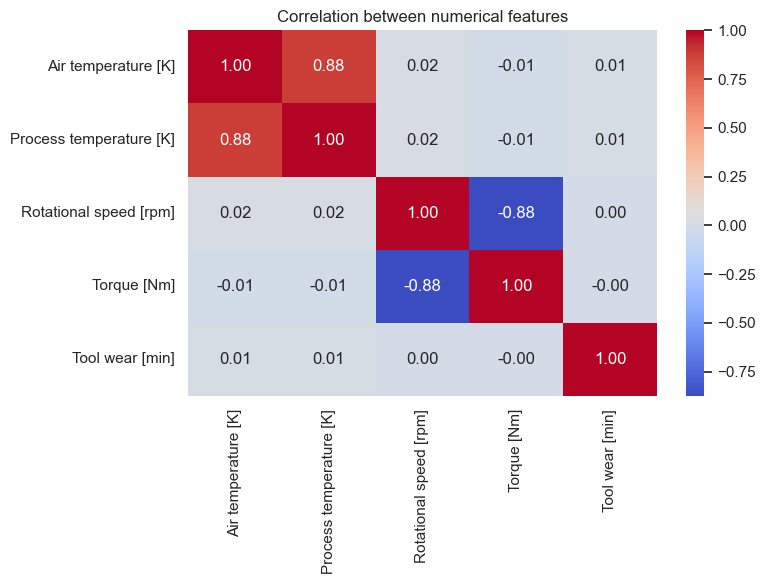

In [40]:
correlation_matrix = df[numerical_features].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numerical features")
plt.tight_layout()
plt.show()

## 11. Failure rate by product type

`Type` is a categorical feature with product categories. This table and chart compare the observed failure rate across the categories.

,Total_records,Failure_count,Failure_rate,Failure_rate_percent
Type,,,,
H,1003,21,0.020937,2.09
L,6000,235,0.039167,3.92
M,2997,83,0.027694,2.77


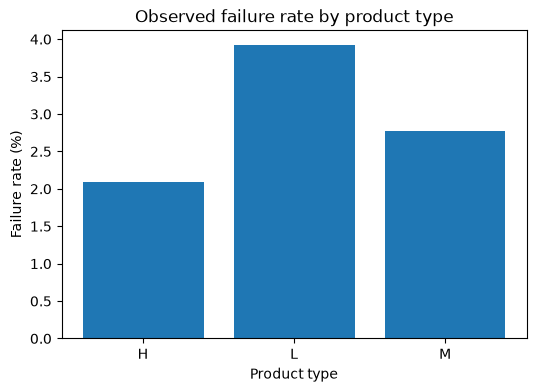

In [12]:
type_summary = df.groupby("Type")["Machine failure"].agg(
    Total_records="count",
    Failure_count="sum",
    Failure_rate="mean"
)
type_summary["Failure_rate_percent"] = (type_summary["Failure_rate"] * 100).round(2)
display(type_summary)

plt.figure(figsize=(6, 4))
plt.bar(type_summary.index, type_summary["Failure_rate_percent"])
plt.title("Observed failure rate by product type")
plt.xlabel("Product type")
plt.ylabel("Failure rate (%)")
plt.show()

## 12. Failure subtype counts (for understanding the dataset only)

The dataset also has columns for specific failure types. These are useful to describe the dataset, but they will **not** be used as input features because they are directly related to the failure outcome and could cause target leakage.

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


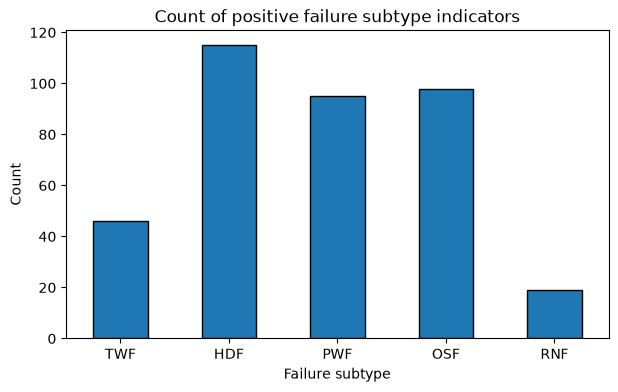

In [13]:
failure_subtypes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[failure_subtypes].sum())

df[failure_subtypes].sum().plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.title("Count of positive failure subtype indicators")
plt.xlabel("Failure subtype")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

## 13. Select input features and target

The six input features are `Type` and the five machine measurements. `UDI` and `Product ID` are identifiers, so they are not useful operating measurements. The five failure subtype columns are also excluded to avoid target leakage.

In [14]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

feature_columns = categorical_features + numerical_features
X = df[feature_columns]
y = df["Machine failure"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Input columns:", list(X.columns))

Input shape: (10000, 6)
Target shape: (10000,)
Input columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


## 14. Split the data into training and testing sets

An 80:20 split is planned. `stratify=y` keeps the class proportions approximately similar in both sets. The test data is kept separate for later model evaluation in Phase 2.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)


Training input shape: (8000, 6)
Testing input shape: (2000, 6)


## 15. Preprocessing pipeline

This uses the lab concepts `SimpleImputer`, `OneHotEncoder`, `StandardScaler`, `ColumnTransformer` and `Pipeline`.

- Numerical columns: fill missing values with the median, then standardise.
- Categorical column: fill missing values with the most frequent category, then one-hot encode.
- The preprocessing is fitted on training data only, then applied to the test data.

The pipeline is defined here as preparation for model implementation in Phase 2.

In [45]:
numerical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessing, numerical_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

# Fit only on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


## 16. Shortlist of machine-learning models for Phase 2

The following models are shortlisted for a later comparison. This Phase 1 notebook defines the plan; model training and performance comparison will be carried out in Phase 2.

| Model | Main idea | Category |
|---|---|---|
| Logistic Regression | Estimates the probability of a class | Linear classifier |
| Decision Tree | Learns decision rules from feature values | Tree-based classifier |
| K-Nearest Neighbours (KNN) | Classifies using nearby observations | Distance-based classifier |
| Support Vector Machine (SVM) | Finds a separating decision boundary | Margin-based classifier |
| Random Forest | Combines multiple decision trees | Ensemble — bagging |
| Gradient Boosting | Adds learners sequentially to improve predictions | Ensemble — boosting |
| XGBoost (if available) | Gradient-boosting implementation | Ensemble — boosting |

Random Forest and Gradient Boosting satisfy the requirement to shortlist at least two ensemble models. The best model cannot be selected until the models are trained and evaluated in Phase 2.

## 17. Phase 1 summary

In this notebook, I:
- loaded and inspected the AI4I dataset;
- listed the metadata and identified the target;
- checked missing values, duplicates and the target distribution;
- explored numerical features, correlations and product type;
- selected six input features and excluded identifiers and failure subtype columns;
- defined and tested the preprocessing pipeline; and
- shortlisted seven candidate models, including three ensemble models.

### Limitations
- The dataset is synthetic and may not represent every real factory.
- Failure cases may be less common than normal observations, so evaluation metrics beyond accuracy will be important.
- The EDA shows patterns and associations; it does not establish causation.
- Model performance and selection are Phase 2 tasks.